In [3]:
import os
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import warnings
from tqdm import tqdm

from sqlalchemy import create_engine
from urllib.parse import quote_plus

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.preprocessing import FunctionTransformer
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

import utils.prediction_utils as pred
from utils import dictionaries as dictionary
from utils.logger import setup_logger

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

# Suppress all warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

In [4]:
class ModelTrainer:
    def __init__(self, test_set_date, cut_off_date, target_groups, numerical_cols, categorical_cols, boolean_cols, target, model_params):
        self.test_set_date = test_set_date
        self.cut_off_date = cut_off_date
        self.target_groups = target_groups
        self.numerical_cols = numerical_cols
        self.categorical_cols = categorical_cols
        self.boolean_cols = boolean_cols
        self.features = numerical_cols + categorical_cols + boolean_cols
        self.target = target
        self.model_params = model_params

        self.query = self.construct_query()
        self.df = self.fetch_and_prep_data(self.query)
        if self.df is None:
            raise ValueError("DataFrame could not be fetched and prepared.")
        self.train_data, self.test_data = self.split_data(self.df, self.test_set_date)
        self.X_train, self.y_train, self.X_test, self.y_test = self.prepare_features_and_target(self.train_data, self.test_data)

        self.best_model = None
        self.best_params = None
        self.results = []
        self.models_df = pd.DataFrame()
        self.shap_values = None
        self.grid_search_objects = []

        self.preprocessor_unscaled = self.create_preprocessor(scaling=False)
        self.preprocessor_scaled = self.create_preprocessor(scaling=True)
        self.models = self.create_models()

    def construct_query(self):
        formatted_target_groups = "', '".join(self.target_groups)
        formatted_target_groups = f"('{formatted_target_groups}')"

        query = f'''
            SELECT b.flight_id,
                   b.target_group,
                   f.advertiser,
                   f.product,
                   f.start_date,
                   f.end_date,
                   b.campaign_duration,
                   b.daypart,
                   f.mock_campaign,
                   f.alcohol_kansspelen,
                   b.total_grp,
                   b.ster_grp,
                   b.regio_grp,
                   b.npo1_grp,
                   b.npo2_grp,
                   b.npo3_grp,
                   b.[ster_1+]
            FROM [dbo].[tv.bereik_ster] b
            LEFT JOIN [dbo].[tv.flights_ster] f ON b.flight_id = f.flight_id
            WHERE b.ster_grp > 0 AND target_group IN {formatted_target_groups}
              AND start_date >= '{self.cut_off_date}'
            ORDER BY start_date
        '''
        return query

    def create_sql_alchemy_engine(self):
        """
        Creates and returns a SQLAlchemy engine for connecting to a SQL Server database.
        """
        quoted = quote_plus(
            "Driver={ODBC+Driver+17+for+SQL+Server};"
            "Server=tcp:stercampsql.database.windows.net;"
            "Database=SterCampNew;"
            "uid=stercampadmin;"
            f"pwd={os.getenv('SQLDB')}"
        )
        alchemy_con = f"mssql+pyodbc:///?odbc_connect={quoted}"
        engine = create_engine(alchemy_con)
        return engine

    def query_to_df(self, query):
        engine = self.create_sql_alchemy_engine()
        df_query = pd.read_sql_query(query, engine)
        return df_query

    def fetch_and_prep_data(self, query):
        try:
            df = self.query_to_df(query)
            df = self.prep_dataframe(df)
            df = self.filter_outliers(df)
        except Exception as e:
            print(f"Error executing query: {str(e)}")
            return None
        return df

    def prep_dataframe(self, df_bereik):


        df = df_bereik[["flight_id", "target_group", "start_date", "end_date", "advertiser", "product", "daypart", "mock_campaign", "alcohol_kansspelen",
                        "npo1_grp", "npo2_grp", "npo3_grp", "regio_grp", "ster_grp",
                        "ster_1+"]].reset_index(drop=True)

        df = (df.pivot_table(index=["flight_id", "target_group", "start_date", "end_date", 'advertiser', 'product', "mock_campaign", "alcohol_kansspelen"],
                            columns='daypart', fill_value=0.0,
                            values=['npo1_grp', 'npo2_grp', 'npo3_grp',
                                    'ster_grp', 'ster_1+', 'regio_grp'], aggfunc='sum').reset_index())

        df.columns = ["_".join(col) if col[1] else col[0] for col in df.columns.to_flat_index()]

        # Convert start_date and end_date to datetime objects and calculate required values
        df['start_date'] = pd.to_datetime(df['start_date'], format="%d%m%y", errors='coerce')
        df['end_date'] = pd.to_datetime(df['end_date'], format="%d%m%y", errors='coerce')

        # Apply function to create extra columns
        df['timef_start_month'] = df['start_date'].dt.month
        df['timef_end_month'] = df['end_date'].dt.month
        df['timef_start_year'] = df['start_date'].dt.year
        df['timef_end_year'] = df['end_date'].dt.year
        df['timef_start_week'] = df['start_date'].dt.strftime("%V").astype(int)
        df['timef_end_week'] = df['end_date'].dt.strftime("%V").astype(int)
        df['timef_start_day'] = df['start_date'].dt.day
        df['timef_end_day'] = df['end_date'].dt.day
        df['timef_duration_days'] = df.apply(lambda row: (row['end_date'] - row['start_date']).days + 1, axis=1)

        df['timef_start_season'] = df['timef_start_month'].apply(lambda month: 'Winter' if month in [12, 1, 2] else
                                                      'Spring' if month in [3, 4, 5] else
                                                      'Summer' if month in [6, 7, 8] else
                                                      'Autumn')
        df['timef_end_season'] = df['timef_end_month'].apply(lambda month: 'Winter' if month in [12, 1, 2] else
                                                    'Spring' if month in [3, 4, 5] else
                                                    'Summer' if month in [6, 7, 8] else
                                                    'Autumn')

        # Calculate total overlap with olympics and WK/EK
        df['timef_olympic_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.olympic_period_list))
        df['timef_football_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.football_wk_ek_list))

        # Create a new column 'data_type' indicating old or new
        df['data_type'] = pd.cut(df['start_date'], bins=[pd.Timestamp.min, pd.to_datetime('2023-09-01'), pd.Timestamp.max], labels=[0, 1])

        df = df.sort_values(by='start_date')

        return df

    def filter_outliers(self, df):

        q_low = df['ster_grp_total'].quantile(0.01)
        q_hi  = df['ster_grp_total'].quantile(0.99)
        df = df[(df['ster_grp_total'] < q_hi) & (df['ster_grp_total'] > q_low)]

        q_low = df['ster_1+_total'].quantile(0.01)
        q_hi  = df['ster_1+_total'].quantile(0.99)
        df = df[(df['ster_1+_total'] < q_hi) & (df['ster_1+_total'] > q_low)]

        return df

    def split_data(self, df, test_set_date):
        train_data = df[df['start_date'] < test_set_date]
        test_data = df[df['start_date'] >= test_set_date]
        return train_data, test_data

    def prepare_features_and_target(self, train_data, test_data):
        X_train = train_data[self.features]
        y_train = train_data[self.target]
        X_test = test_data[self.features]
        y_test = test_data[self.target]
        return X_train, y_train, X_test, y_test

    def create_preprocessor(self, scaling=True):
        numerical_transformer_steps = [('imputer', SimpleImputer(strategy='mean'))]
        if scaling:
            numerical_transformer_steps.append(('scaler', StandardScaler()))

        numerical_transformer = Pipeline(steps=numerical_transformer_steps)

        categorical_transformer = Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))])

        boolean_transformer = Pipeline(steps=[
            ('int_conversion', FunctionTransformer(lambda x: x.astype(int), validate=False)),
            ('imputer', SimpleImputer(strategy='most_frequent'))])

        transformers = []
        transformers.append(('num', numerical_transformer, self.numerical_cols))
        transformers.append(('cat', categorical_transformer, self.categorical_cols))
        transformers.append(('bool', boolean_transformer, self.boolean_cols))

        preprocessor = ColumnTransformer(transformers=transformers)

        return preprocessor

    def create_models(self):
        models = []
        for model_info in self.model_params:
            models.append({
                'name': model_info['name'],
                'model': model_info['model'],
                'params': model_info['params'],
                'preprocessor': self.preprocessor_unscaled if model_info['scaling'] == 'unscaled' else self.preprocessor_scaled
            })

        return models

    def grid_search_models(self):
        models_data = {
            'Model': [],
            'Parameters': [],
            'R2 Train': [],
            'R2 Test': [],
            'MSE Train': [],
            'MSE Test': [],
            'MAE Train': [],
            'MAE Test': []
        }

        tscv = TimeSeriesSplit(n_splits=5)
        total_iterations = sum(len(ParameterGrid(model_info['params'])) for model_info in self.models) * tscv.get_n_splits(self.X_train)
        pbar = tqdm(total=total_iterations, desc="Grid Search Progress")

        for model_info in self.models:
            pipeline = Pipeline(steps=[
                ('preprocessor', model_info['preprocessor']),
                ('model', model_info['model'])
            ])

            grid_search = GridSearchCV(
                estimator=pipeline,
                param_grid=model_info['params'],
                cv=tscv,
                scoring='neg_mean_squared_error',
                n_jobs=-1,
                return_train_score=True,
                verbose=1
            )

            grid_search.fit(self.X_train, self.y_train)
            pbar.update(len(ParameterGrid(model_info['params'])) * tscv.get_n_splits(self.X_train))

            self.grid_search_objects.append(grid_search)
            results_df = pd.DataFrame(grid_search.cv_results_)
            self.results.append(results_df)

            if grid_search.best_score_ > (self.best_score if self.best_model else float('-inf')):
                self.best_score = grid_search.best_score_
                self.best_model = grid_search.best_estimator_
                self.best_params = grid_search.best_params_

            y_train_pred = grid_search.predict(self.X_train)
            y_test_pred = grid_search.predict(self.X_test)

            r2_train = r2_score(self.y_train, y_train_pred)
            r2_test = r2_score(self.y_test, y_test_pred)
            mse_train = mean_squared_error(self.y_train, y_train_pred)
            mse_test = mean_squared_error(self.y_test, y_test_pred)
            mae_train = mean_absolute_error(self.y_train, y_train_pred)
            mae_test = mean_absolute_error(self.y_test, y_test_pred)

            models_data['Model'].append(model_info['name'])
            models_data['Parameters'].append(grid_search.best_params_)
            models_data['R2 Train'].append(r2_train)
            models_data['R2 Test'].append(r2_test)
            models_data['MSE Train'].append(mse_train)
            models_data['MSE Test'].append(mse_test)
            models_data['MAE Train'].append(mae_train)
            models_data['MAE Test'].append(mae_test)

        pbar.close()
        self.models_df = pd.DataFrame(models_data)
        print(f"Best Model: {self.best_model}")
        print(f"Best Parameters: {self.best_params}")

    def get_feature_names(self, preprocessor):
        feature_names = []

        # Get numerical feature names
        if 'num' in preprocessor.named_transformers_:
            feature_names += self.numerical_cols

        # Get categorical feature names
        if 'cat' in preprocessor.named_transformers_:
            encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
            cat_feature_names = encoder.get_feature_names_out(self.categorical_cols)
            feature_names += cat_feature_names.tolist()

        # Get boolean feature names
        if 'bool' in preprocessor.named_transformers_:
            feature_names += self.boolean_cols

        return feature_names

    def extract_and_visualize_shap_values(self):
        if self.best_model is None:
            print("No best model found. Please run grid_search_models first.")
            return

        explainer = shap.Explainer(self.best_model.named_steps['model'])
        self.shap_values = explainer(self.best_model.named_steps['preprocessor'].transform(self.X_test))
        feature_names = self.get_feature_names(self.best_model.named_steps['preprocessor'])
        self.visualize_shap_values(self.shap_values, self.best_model.named_steps['preprocessor'].transform(self.X_test), feature_names)

    def visualize_shap_values(self, shap_values, X_test_transformed, feature_names):
        if shap_values is None:
            print("No SHAP values to visualize.")
            return

        # Convert to DataFrame for better handling of feature names
        X_test_transformed_df = pd.DataFrame(X_test_transformed, columns=feature_names)

        # Summary plot
        shap.summary_plot(shap_values, X_test_transformed_df, plot_size=[8, 6])

        # Check if SHAP values are in the right format for dependence plot
        if isinstance(shap_values, shap.Explanation):
            # Dependence plot (example for the first feature)
            shap.dependence_plot(1, shap_values.values, X_test_transformed_df, feature_names=feature_names)
        else:
            print("SHAP values are not in the expected format for dependence plot.")

        # Bar plot of feature importances
        shap.summary_plot(shap_values, X_test_transformed_df, plot_type="bar", plot_size=[8, 6])

    def extract_best_model_details(self):
        if self.best_model is None:
            print("No best model found. Please run grid_search_models first.")
            return

        print("Best Model:")
        print(self.best_model)

        print("\nBest Parameters:")
        print(self.best_params)

        print("\nPreprocessor:")
        preprocessor = self.best_model.named_steps['preprocessor']
        print(preprocessor)

        if isinstance(preprocessor, ColumnTransformer):
            transformers = preprocessor.transformers
            for name, transformer, columns in transformers:
                print(f"\n{name} Transformer:")
                print(f"Columns: {columns}")
                print(f"Transformer: {transformer}")


In [5]:
# Define the parameters for the ModelTrainer instance
TEST_SET_DATE = pd.to_datetime('2024-05-01') # start datum van test set (als timeseries wordt aanghouden)
CUT_OFF_DATE = '2023-09-01' # inclusief of exclusief oude data
TARGET_GROUPS = ['25-67'] # kan ook met meerdere target groups als feature

NUMERICAL_COLS = ['npo1_grp_daynight', 'npo1_grp_primetime', 'npo1_grp_total',
                  'npo2_grp_daynight', 'npo2_grp_primetime', 'npo2_grp_total',
                  'npo3_grp_daynight', 'npo3_grp_primetime', 'npo3_grp_total',
                  'regio_grp_daynight', 'regio_grp_primetime', 'regio_grp_total',
                  'timef_start_month', 'timef_end_month', 'timef_start_week', 'timef_end_week',
                  'timef_start_year', 'timef_end_year', 'timef_start_day', 'timef_end_day', 'timef_duration_days', 'timef_olympic_period_overlap', 'timef_football_period_overlap'
                  ]

CATEGORICAL_COLS = ['target_group', 'timef_start_season', 'timef_end_season']
BOOLEAN_COLS = ['alcohol_kansspelen', 'data_type']
TARGET = 'ster_1+_total'

# Tweaken kan met dexe parameters (of meerdere modellen) met al dan niet scaling. Dit is zo'n beetje het minimale (met 2 modellen) om te testen.
MODEL_PARAMS = [
    {
        'name': 'XGB without scaling',
        'model': XGBRegressor(objective='reg:squarederror'),
        'params': {
            'model__colsample_bytree': [0.8, 1.0],
            'model__random_state': [42]
        },
        'scaling': 'unscaled'
    },
    {
        'name': 'LGBM without scaling',
        'model': LGBMRegressor(objective='regression'),
        'params': {
            'model__num_leaves': [30, 70]
        },
        'scaling': 'unscaled'
    }
]

# Create an instance of ModelTrainer
trainer = ModelTrainer(
    test_set_date=TEST_SET_DATE,
    cut_off_date=CUT_OFF_DATE,
    target_groups=TARGET_GROUPS,
    numerical_cols=NUMERICAL_COLS,
    categorical_cols=CATEGORICAL_COLS,
    boolean_cols=BOOLEAN_COLS,
    target=TARGET,
    model_params=MODEL_PARAMS
)

In [ ]:
# Extreme parameter tweaking. Nog niet nodig
'''
MODEL_PARAMS = [
    {
        'name': 'XGB without scaling',
        'model': XGBRegressor(objective='reg:squarederror'),
        'params': {
            'model__colsample_bytree': [0.8, 1.0],
            'model__gamma': [0.4, 0.6, 0.8],
            'model__learning_rate': [0.01, 0.05, 0.1],
            'model__max_depth': [5, 10, 15],
            'model__min_child_weight': [1, 5, 10],
            'model__n_estimators': [200, 400, 600],
            'model__reg_alpha': [0, 0.05, 0.1],
            'model__reg_lambda': [1, 2, 3],
            'model__subsample': [0.3, 0.6, 0.9],
            'model__random_state': [42]
        },
        'scaling': 'scaled'
    },
    {
        'name': 'LGBM without scaling',
        'model': LGBMRegressor(objective='regression'),
        'params': {
            'model__num_leaves': [30, 50, 70],
            'model__max_depth': [3, 5, 8],
            'model__learning_rate': [0.01, 0.05, 0.1],
            'model__n_estimators': [200, 400, 600],
            'model__subsample': [0.7, 0.8, 0.9],
            'model__colsample_bytree': [0.7, 0.8, 1.0],
            'model__reg_alpha': [0, 0.1, 0.3],
            'model__reg_lambda': [0, 1, 3],
            'model__random_state': [42]
        },
        'scaling': 'unscaled'
    }
]

'''

In [ ]:
# Zo kunnen functies apart worden aangeroepen uit de Class. Handig om mee te testen, maar niet nodig voor het hele process. Deze worden al aangeroepen door de Class zelf.

'''
query = trainer.construct_query()
df = trainer.fetch_and_prep_data(query)

train_data, test_data = trainer.split_data(df, TEST_SET_DATE)
X_train, y_train, X_test, y_test = trainer.prepare_features_and_target(train_data, test_data)
'''


In [7]:
# Train modellen met CV en gekozen features.
trainer.grid_search_models()
print(trainer.models_df)

Grid Search Progress:   0%|          | 0/20 [00:00<?, ?it/s]

Fitting 5 folds for each of 2 candidates, totalling 10 fits


Grid Search Progress:  50%|█████     | 10/20 [00:01<00:01,  5.77it/s]

Fitting 5 folds for each of 2 candidates, totalling 10 fits
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000740 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3169
[LightGBM] [Info] Number of data points in the train set: 4536, number of used features: 27
[LightGBM] [Info] Start training from score 24.104866


Grid Search Progress: 100%|██████████| 20/20 [00:06<00:00,  3.22it/s]

Best Model: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer())]),
                                                  ['npo1_grp_daynight',
                                                   'npo1_grp_primetime',
                                                   'npo1_grp_total',
                                                   'npo2_grp_daynight',
                                                   'npo2_grp_primetime',
                                                   'npo2_grp_total',
                                                   'npo3_grp_daynight',
                                                   'npo3_grp_primetime',
                                                   'npo3_grp_total',
                                                   'regio_grp_daynight',
                  

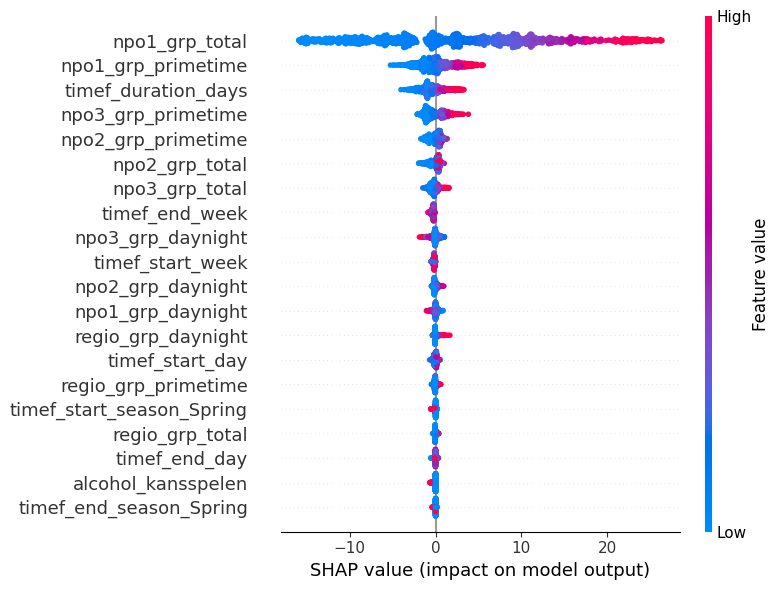

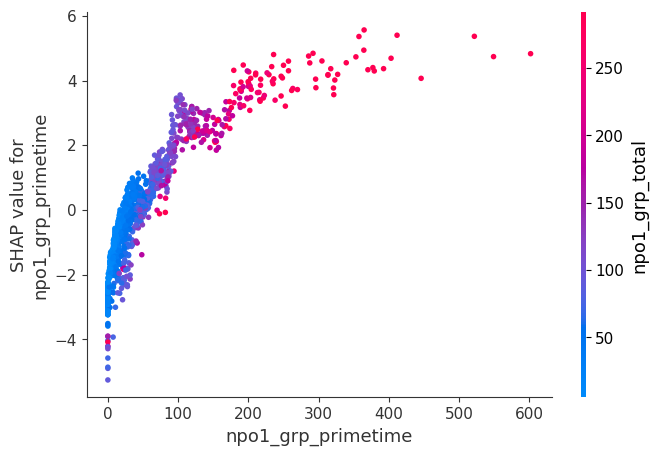

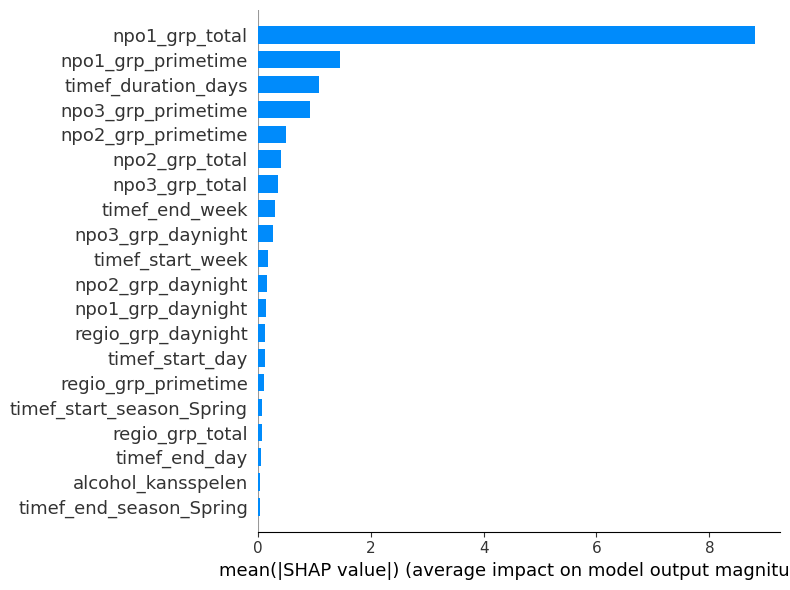

In [8]:
trainer.extract_and_visualize_shap_values()

In [9]:
trainer.extract_best_model_details()

Best Model:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer())]),
                                                  ['npo1_grp_daynight',
                                                   'npo1_grp_primetime',
                                                   'npo1_grp_total',
                                                   'npo2_grp_daynight',
                                                   'npo2_grp_primetime',
                                                   'npo2_grp_total',
                                                   'npo3_grp_daynight',
                                                   'npo3_grp_primetime',
                                                   'npo3_grp_total',
                                                   'regio_grp_daynight',
                  